# 16 · Camera and stage acquisition workflow: build it step by step

A through-focus scan pairs each camera frame with a stage position and acquisition settings. This lesson uses a simulated scan by default; the optional hardware cell shows the existing Thorlabs and Basler connection pattern without moving a stage.

This companion defines the small analysis functions alongside the measurement workflow.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Keep positions and frames together

A scan is a sequence of `(position, frame)` pairs. A small container function helps prevent accidental mismatch between filenames and stage locations.

In [ ]:
def pair_positions_and_frames(positions_mm, frames):
    """Validate and return a position-indexed frame stack."""
    positions_mm = np.asarray(positions_mm)
    frames = np.asarray(frames)
    if frames.shape[0] != positions_mm.size:
        raise ValueError("Need exactly one frame for each position.")
    return positions_mm, frames

z_mm = np.linspace(-1, 1, 9)
x_px = np.arange(128)
profiles = np.array([np.exp(-(x_px-64)**2/(2*(12+4*abs(z))**2)) for z in z_mm])
z_mm, profiles = pair_positions_and_frames(z_mm, profiles)


## 2. Define a single-frame acquisition helper

Keep instrument calls inside a small function so exposure, timeout, and cleanup are explicit. The function is not called by this lesson; it can be used after you have connected the intended camera at the bench.

In [ ]:
def acquire_one_frame(camera, pylon, exposure_us=75, timeout_ms=5000):
    """Acquire one Basler frame and return a copied NumPy array."""
    camera.ExposureTime.SetValue(exposure_us)
    camera.StartGrabbingMax(1)
    result = camera.RetrieveResult(timeout_ms, pylon.TimeoutHandling_ThrowException)
    try:
        if not result.GrabSucceeded():
            raise RuntimeError(result.GetErrorDescription())
        return result.Array.copy()
    finally:
        result.Release()


## 3. Store the acquisition settings with the scan

A metadata dictionary keeps experimental settings next to the measurements. The following lesson shows how to package this with the acquired arrays.

In [ ]:
def scan_metadata(wavelength_m, exposure_us, pixel_size_um, positions_mm):
    """Collect the calibration and scan axis needed to interpret frames."""
    return {"wavelength_m": float(wavelength_m), "exposure_us": float(exposure_us),
            "pixel_size_um": float(pixel_size_um), "positions_mm": np.asarray(positions_mm).tolist()}

metadata = scan_metadata(633e-9, 75, 3.45, z_mm)
print(metadata)


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/2026.03.02LensDataPt3.ipynb`, cell 9.


In [ ]:
def acquire_and_plot_image(camera, exposure_time_us=480, unit='um', scalebar_length_um=100, figsize=(6,4), title=None):
    """
    Acquire one image from the camera and plot it with physical axes.
    
    Parameters:
    -----------
    camera : pypylon.pylon.InstantCamera
        The camera instance to acquire from
    exposure_time_us : float, optional
        Exposure time in microseconds (default: 19)
    unit : str, optional
        'um' or 'mm' for axis units (default: 'um')
    scalebar_length_um : float, optional
        Length of scalebar in micrometers (default: 100)
    figsize : tuple, optional
        Figure size (default: (6,4))
    title : str, optional
        Custom title for the plot. If None, uses default format (default: None)
    
    Returns:
    --------
    image : numpy.ndarray
        The acquired image
    pixel_size_um : float
        The pixel size in micrometers
    """
    import numpy as np
    from matplotlib import pyplot as plt
    from pypylon import pylon

    if not camera.IsOpen():
        camera.Open()

    def _set_exposure(cam, exposure_us):
        try:
            cam.ExposureTime.SetValue(exposure_us)
            return True
        except Exception:
            pass
        try:
            nodemap = cam.GetNodeMap()
            for name in ("ExposureTime", "ExposureTimeAbs", "ExposureTimeRaw"):
                try:
                    node = nodemap.GetNode(name)
                    if node is None:
                        continue
                    if hasattr(node, "IsWritable") and not node.IsWritable():
                        continue
                    try:
                        node.SetValue(exposure_us)
                        return True
                    except Exception:
                        pass
                except Exception:
                    continue
        except Exception:
            pass
        return False

    if not _set_exposure(camera, exposure_time_us):
        print("Warning: Exposure time node not available; using current exposure.")
    
    # Set exposure and acquire
    camera.StartGrabbingMax(1)
    grab_result = camera.RetrieveResult(5000, pylon.TimeoutHandling_ThrowException)
    
    if grab_result.GrabSucceeded():
        image = grab_result.Array
        # print(f"Image acquired successfully. Shape: {image.shape}")
    else:
        print("Image grab failed")
        grab_result.Release()
        camera.StopGrabbing()
        return None, None
    
    grab_result.Release()
    camera.StopGrabbing()
    
    # Determine pixel size
    def _try_get_node_value(nodemap, candidates):
        for name in candidates:
            try:
                node = nodemap.GetNode(name)
                if node is not None:
                    try:
                        val = node.GetValue()
                    except Exception:
                        try:
                            val = float(node.ToString())
                        except Exception:
                            val = None
                    if val is not None:
                        return float(val)
            except Exception:
                continue
        return None
    
    model = camera.GetDeviceInfo().GetModelName()
    pixel_size_um = None
    
    if any(k in model for k in ("a2A1920-51gc", "a2A1920-51", "IMX392")):
        pixel_size_um = 3.45
    
    if pixel_size_um is None:
        try:
            nodemap = camera.GetNodeMap()
            pixel_size_um = _try_get_node_value(nodemap, ["PixelSize", "PixelSizeX", "PixelSizeUm", "PixelPitch"])
            if pixel_size_um is None:
                sensor_width = _try_get_node_value(nodemap, ["SensorWidth", "SensorWidth_mm", "SensorWidth_um"])
                if sensor_width is not None:
                    sensor_width_mm = sensor_width if sensor_width < 10 else sensor_width / 1000.0
                    pixel_size_um = (sensor_width_mm * 1000.0) / image.shape[1]
        except Exception:
            pass
    
    if pixel_size_um is None:
        try:
            pixel_size_um = float(input("Pixel size (µm) not found. Enter pixel size in micrometers: ").strip())
        except Exception:
            raise RuntimeError("Pixel size not available from camera; please provide it manually.")
    
    # print(f"Camera model: {model}")
    # print(f"Using pixel size: {pixel_size_um:.3f} µm (X/Y assumed equal)")
    
    # Plot with physical axes
    def add_scalebar(ax, length_um, pixel_size_um, location='lower right', color='white', fontsize=10):
        length_data = length_um
        xlim = ax.get_xlim()
        ylim = ax.get_ylim()
        if location == 'lower right':
            x = xlim[1] - (xlim[1] - xlim[0]) * 0.05 - length_data
            y = ylim[0] + (ylim[1] - ylim[0]) * 0.05
        else:
            x = xlim[0] + (xlim[1] - xlim[0]) * 0.05
            y = ylim[0] + (ylim[1] - ylim[0]) * 0.05
        ax.plot([x, x + length_data], [y, y], color=color, linewidth=3)
        ax.text(x + length_data / 2, y + (ylim[1] - ylim[0]) * 0.02, f"{length_um:g} µm",
                color=color, ha='center', va='bottom', fontsize=fontsize)
    
    h, w = image.shape[:2]
    if unit == 'um':
        x_max = w * pixel_size_um
        y_max = h * pixel_size_um
        xlabel, ylabel = 'X (µm)', 'Y (µm)'
    elif unit == 'mm':
        x_max = w * pixel_size_um / 1000.0
        y_max = h * pixel_size_um / 1000.0
        xlabel, ylabel = 'X (mm)', 'Y (mm)'
    else:
        raise ValueError("unit must be 'um' or 'mm'")
    
    extent = (0, x_max, 0, y_max)
    plt.figure(figsize=figsize)
    ax = plt.gca()
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None, extent=extent, origin='lower')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    
    # Use custom title if provided, otherwise use default format
    if title is None:
        plt.title(f"{model} — pixel {pixel_size_um:.2f} µm")
    else:
        plt.title(title)
    
    plt.tight_layout()
    
    try:
        add_scalebar(ax, scalebar_length_um, pixel_size_um, color='white')
    except Exception:
        pass
    
    plt.colorbar(label='Pixel Intensity [ADU]')
    plt.show()
    
    return image, pixel_size_um

The figure-producing function above is from the paper notebook. This is the same acquisition call used for its saved frame; it assumes the camera has already been connected.


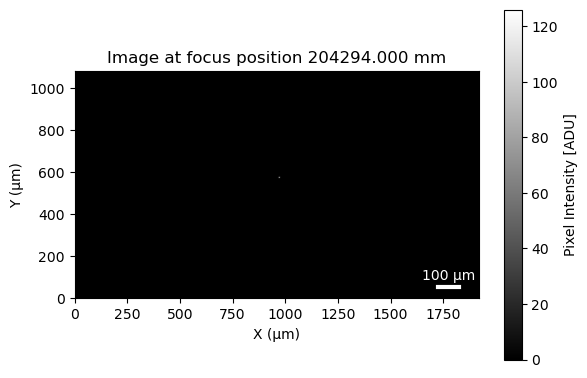

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
 1.0)

In [ ]:
acquire_and_plot_image(camera, title='Image at focus position {:.3f} mm'.format(focus_pos_ct))
